# Leilões de rodovias federais: qual vale a pena disputar?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/marialuisagama/leiloes-rodovias/blob/main/triagem_leiloes.ipynb)

**Pergunta do projeto:** entre os leilões de rodovias federais recentes e previstos, qual é o mais atraente para um investidor de equity de infraestrutura, e quanto vale ganhar esse leilão?

**Por que essa pergunta.** De 2023 a 2026, o governo federal leiloou cerca de vinte lotes de rodovias, e fundos de infraestrutura passaram a disputar esses leilões ao lado das operadoras tradicionais. Quem entra num leilão precisa responder duas coisas: *qual lote vale o esforço* e *até onde dá para baixar a tarifa sem destruir o retorno*. Este projeto responde as duas, nessa ordem.

**Como o projeto está organizado**
1. **Triagem (este notebook, em Python):** aprender com os leilões que já aconteceram o que explica o desconto oferecido e escolher um lote para estudar a fundo.
2. **Modelo de project finance (Excel):** projetar receita, capex, opex e dívida do lote escolhido e calcular o desconto máximo que ainda entrega o retorno exigido pelo investidor.

**Resumo dos achados da triagem**
- A **concorrência** explica a maior parte do desconto: com uma proposta, o desconto fica perto de zero; com três ou mais, costuma ficar entre 14% e 27%.
- Características do lote (capex por km, tamanho do investimento, duplicação, TIR de referência) **não** explicam bem o desconto.
- Entre os finalistas, nem a **economia da região** nem o **tráfego** preveem quantos concorrentes aparecem.
- Conclusão: o desconto não é previsível a partir dos fundamentos. Por isso, o modelo vai tratar o desconto como **resultado** (o máximo que o investidor pode oferecer), e não como premissa.

## Antes de começar: dois conceitos que parecem iguais e não são

| | **Desconto na tarifa** (o lance) | **Taxa de desconto** (o retorno exigido) |
|---|---|---|
| O que é | Quanto o vencedor reduz a tarifa teto definida pelo governo | A taxa usada para trazer fluxos futuros a valor presente |
| Quem define | O proponente, no leilão | O investidor, conforme o risco do ativo |
| Efeito no valor | Desconto maior = menos receita = projeto vale menos | Taxa maior = fluxos futuros valem menos hoje |

**Como funciona o leilão.** O governo publica uma *tarifa teto*, calculada para que o projeto renda a **TIR de referência** (o retorno que o governo considera justo). Vence quem oferecer o **maior desconto** sobre essa tarifa. Nos modelos mais recentes, descontos acima de certo limite exigem um **aporte** de capital do vencedor, uma garantia contra lances irresponsáveis.

Intuição: quanto maior o desconto, mais o vencedor aceitou ganhar menos que a TIR de referência. Desconto alto é sinal de disputa (ou de otimismo).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# estilo dos gráficos: eixos limpos e grade discreta
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
})
AZUL, LARANJA, VERDE, AMARELO, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#9b9a97"

url = "https://raw.githubusercontent.com/marialuisagama/leiloes-rodovias/main/dados/leiloes_rodovias.xlsx"
df = pd.read_excel(url, sheet_name="leiloes")
regiao = pd.read_excel(url, sheet_name="regiao")

# variáveis derivadas
df["capex_por_km"] = df["capex_bi"] * 1000 / df["extensao_km"]   # R$ milhões por km
df["pct_duplicacao"] = df["duplicacao_km"] / df["extensao_km"]

# datas: algumas vêm como dd/mm/aaaa, outras só como mês/ano ("dez/2025")
meses = {"jan": 1, "fev": 2, "mar": 3, "abr": 4, "mai": 5, "jun": 6,
         "jul": 7, "ago": 8, "set": 9, "out": 10, "nov": 11, "dez": 12}
def ler_data(s):
    s = str(s).strip()
    if s[:3] in meses:                       # formato mês/ano: uso o dia 15
        return pd.Timestamp(int(s[-4:]), meses[s[:3]], 15)
    return pd.to_datetime(s, dayfirst=True, errors="coerce")
df["data"] = df["data_leilao"].map(ler_data)

# faixas de concorrência (uso faixas porque há poucos leilões em cada número exato)
def faixa(n):
    if pd.isna(n): return "sem dado"
    return "1 proposta" if n == 1 else ("2 propostas" if n == 2 else "3 ou mais")
df["concorrencia"] = df["n_propostas"].map(faixa)
COR_FAIXA = {"1 proposta": "#86b6ec", "2 propostas": AZUL, "3 ou mais": "#0f4c96", "sem dado": CINZA}

realizados = df[df["status"] == "realizado"].copy()
previstos = df[df["status"] == "previsto"].copy()
print(f"{len(realizados)} leilões realizados e {len(previstos)} previstos")
print(f"Com desconto conhecido: {realizados['desconto'].notna().sum()} | com nº de propostas: {realizados['n_propostas'].notna().sum()}")

18 leilões realizados e 4 previstos
Com desconto conhecido: 14 | com nº de propostas: 14


## 1. O universo: o que entrou na base e por quê

**Escolhas e motivos**
- **Só leilões federais (ANTT), de 2023 a 2026.** É o ciclo atual de concessões, com contratos parecidos entre si (mesmo tipo de edital, mesma lógica de tarifa teto e aporte), o que permite comparar um leilão com outro. Os lotes do Paraná entram porque foram leiloados pela ANTT (reúnem rodovias federais e estaduais delegadas à União). Leilões estaduais de outros estados usam regras diferentes e ficaram de fora.
- **Fontes:** páginas de cada projeto na ANTT (extensão, capex, opex, TIR de referência, tarifa teto) e imprensa especializada (vencedor, desconto, número de propostas). Cada linha da planilha tem a fonte.
- **Lacunas:** alguns leilões não têm desconto ou número de propostas publicado. Prefiro deixar em branco a estimar: um número inventado contaminaria exatamente a relação que quero testar.

O gráfico abaixo mostra a linha do tempo: cada bolha é um leilão, a altura é o desconto, o tamanho é o capex e a cor é o nível de concorrência.

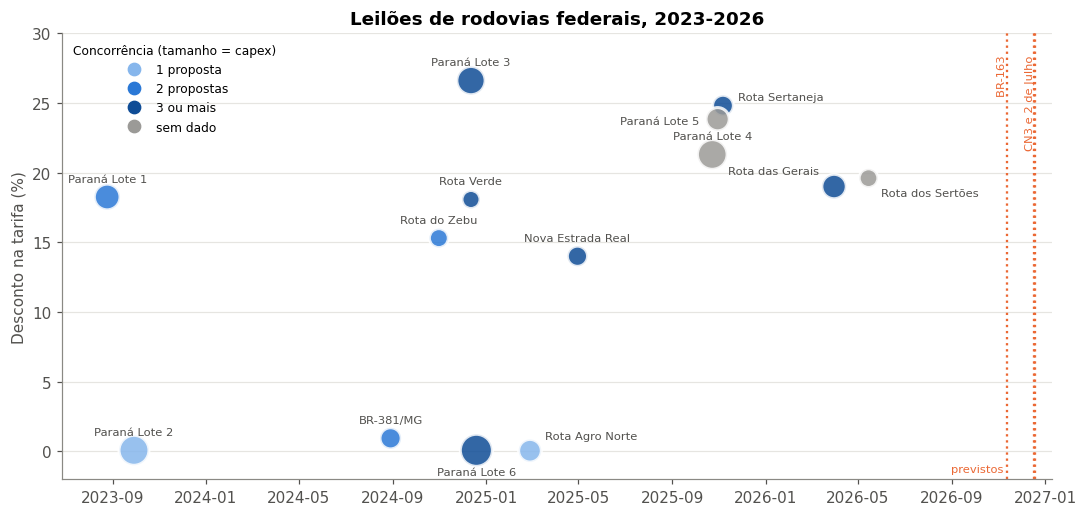

In [2]:
fig, ax = plt.subplots(figsize=(10, 4.8))
base = realizados.dropna(subset=["data", "desconto"])
for nome_faixa, g in base.groupby("concorrencia"):
    ax.scatter(g["data"], g["desconto"] * 100, s=g["capex_bi"].fillna(5) * 35,
               color=COR_FAIXA[nome_faixa], alpha=0.85, edgecolor="white", linewidth=2,
               label=nome_faixa, zorder=3)
# posição de cada rótulo (em pontos, relativa à bolha) para evitar sobreposição
desloc = {"Paraná Lote 6": (0, -16, "center"), "Rota Agro Norte (CN5)": (10, 8, "left"),
          "Paraná Lote 5": (-12, -3, "right"), "Rota Sertaneja": (10, 4, "left"),
          "Rota dos Sertões": (8, -12, "left"), "Rota das Gerais": (-10, 8, "right")}
for _, r in base.iterrows():
    dx, dy, ha = desloc.get(r["leilao"], (0, 10, "center"))
    ax.annotate(r["leilao"].split(" (")[0], (r["data"], r["desconto"] * 100),
                xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=7.5, color="#52514e")

# leilões previstos: linhas verticais no futuro (CN3 e 2 de Julho são na mesma semana)
prev = previstos.dropna(subset=["data"]).sort_values("data")
for _, r in prev.iterrows():
    ax.axvline(r["data"], color=LARANJA, linestyle=":", linewidth=1.5, zorder=1)
ax.text(prev["data"].iloc[0], 29, "BR-163  ", rotation=90, va="top", ha="right", fontsize=7.5, color=LARANJA)
ax.text(prev["data"].iloc[-1], 29, "CN3 e 2 de Julho  ", rotation=90, va="top", ha="right", fontsize=7.5, color=LARANJA)
ax.text(prev["data"].iloc[0], -1.5, "previstos ", ha="right", fontsize=7.5, color=LARANJA)

ax.set_ylim(-2, 30)
ax.set_ylabel("Desconto na tarifa (%)")
ax.set_title("Leilões de rodovias federais, 2023-2026")
from matplotlib.lines import Line2D
marcas = [Line2D([], [], marker="o", linestyle="", markersize=8, color=c, label=f) for f, c in COR_FAIXA.items()]
ax.legend(handles=marcas, title="Concorrência (tamanho = capex)", loc="upper left", fontsize=8, title_fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

**O que o gráfico mostra.** Os descontos se espalham de 0% a 27%, sem tendência clara no tempo: há leilões com desconto zero tanto em 2023 (Paraná Lote 2) quanto em 2025 (Rota Agro Norte). As bolhas mais escuras (mais concorrência) ficam quase sempre no alto. As linhas laranja marcam os leilões previstos até o fim de 2026.

## 2. O que explica o desconto?

Antes de olhar os dados, listei o que, na teoria, deveria levar um proponente a oferecer mais desconto:

| Hipótese | Por que faria sentido | Como medi |
|---|---|---|
| **Concorrência** | Com mais rivais, quem quer ganhar precisa abrir mão de retorno | Número de propostas |
| **Risco de obra** | Obras caras por km (serra, várzea, duplicação) têm mais risco de estouro; o proponente se protege com menos desconto | Capex por km |
| **Tamanho do cheque** | Projetos grandes afastam proponentes menores e reduzem a disputa | Capex total |
| **Peso da duplicação** | Duplicar é a parte mais arriscada da obra | % da extensão a duplicar |
| **Folga na TIR de referência** | Se o governo calibrou a tarifa com uma TIR alta, sobra espaço para desconto | TIR de referência |

### 2.1 Concorrência

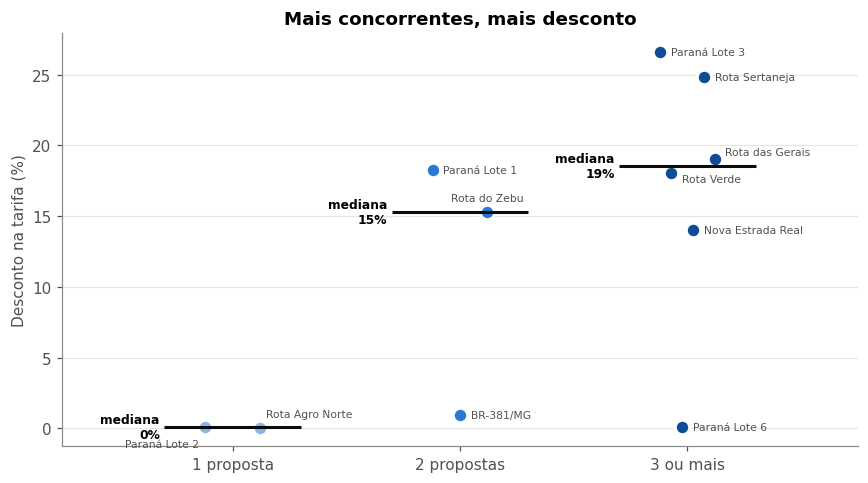

              count  median    min    max
concorrencia                             
1 proposta        2   0.001  0.000  0.001
2 propostas       3   0.153  0.009  0.182
3 ou mais         6   0.185  0.001  0.266


In [3]:
ordem = ["1 proposta", "2 propostas", "3 ou mais"]
base = realizados.dropna(subset=["desconto", "n_propostas"])

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, f in enumerate(ordem):
    g = base[base["concorrencia"] == f]
    x = np.full(len(g), i) + np.linspace(-0.12, 0.12, len(g))      # espalha os pontos para não sobrepor
    ax.scatter(x, g["desconto"] * 100, s=90, color=COR_FAIXA[f], edgecolor="white", linewidth=2, zorder=3)
    ax.hlines(g["desconto"].median() * 100, i - 0.3, i + 0.3, color="#0b0b0b", linewidth=2, zorder=4)
    ax.text(i - 0.32, g["desconto"].median() * 100, f"mediana\n{g['desconto'].median():.0%}", va="center",
            ha="right", fontsize=8, fontweight="bold")
    pos = {"Paraná Lote 2": (-4, -11, "right"), "Rota Agro Norte (CN5)": (4, 9, "left"), "Rota do Zebu": (0, 9, "center"),
           "Rota das Gerais": (7, 5, "left"), "Rota Verde (CN1)": (7, -4, "left")}
    for xi, (_, r) in zip(x, g.iterrows()):
        dx, dy, ha = pos.get(r["leilao"], (7, 0, "left"))
        ax.annotate(r["leilao"].split(" (")[0], (xi, r["desconto"] * 100), xytext=(dx, dy),
                    textcoords="offset points", fontsize=7, color="#52514e", va="center", ha=ha)
ax.set_xticks(range(3), ordem)
ax.set_xlim(-0.75, 2.75)
ax.set_ylabel("Desconto na tarifa (%)")
ax.set_title("Mais concorrentes, mais desconto")
plt.tight_layout(); plt.show()

print(base.groupby("concorrencia")["desconto"].agg(["count", "median", "min", "max"]).loc[ordem].round(3))

**Leitura.** É a relação mais forte da base.
- **Uma proposta:** desconto praticamente zero (0,05% a 0,08%). Sem rival, não há motivo para abrir mão de retorno.
- **Três ou mais:** quase sempre entre 14% e 27%.
- **Duas propostas:** resultado misto (BR-381 com 0,9%, Paraná Lote 1 com 18%). Com dois concorrentes, depende de quanto cada um quer o ativo.

**A exceção que merece explicação: Paraná Lote 6.** Quatro propostas e desconto de 0,08%. Esse lote obriga a duplicar 462 dos 662 km, o maior capex por km da base (cerca de R$ 19 milhões). A obra é tão pesada que ninguém quis abrir mão de retorno, mesmo com rivais. Testo isso na seção 2.2.

**Cuidado:** concorrência e desconto são decididos *juntos*, no mesmo dia. O número de propostas não é algo que o investidor conhece antes de dar o lance, então essa relação explica o passado, mas não ajuda a prever o próximo leilão. Por isso as hipóteses seguintes procuram características que **se conhecem antes** do leilão.

### 2.2 Características do lote

Os quatro gráficos abaixo testam as hipóteses que se conhecem antes do leilão. Cada ponto é um leilão; a cor continua sendo a concorrência; o **r** no título é a correlação (vai de −1 a 1; perto de zero quer dizer "sem relação").

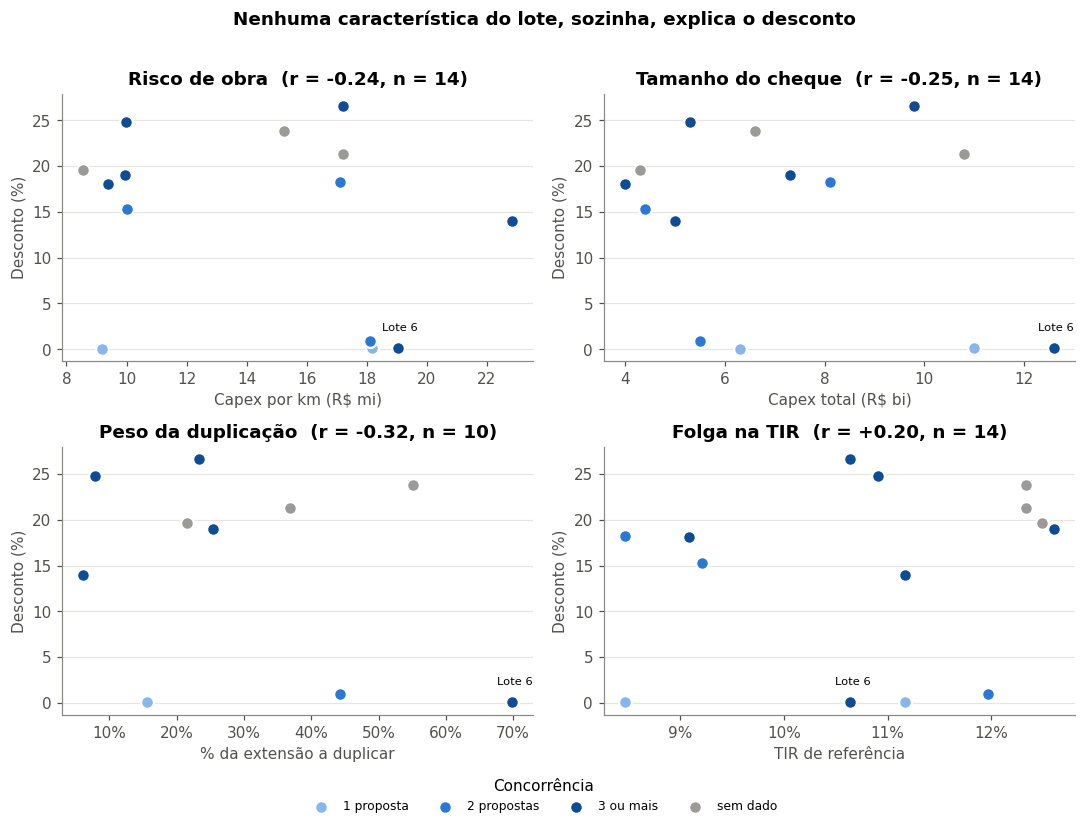

In [4]:
testes = [("capex_por_km", "Capex por km (R$ mi)", "Risco de obra"),
          ("capex_bi", "Capex total (R$ bi)", "Tamanho do cheque"),
          ("pct_duplicacao", "% da extensão a duplicar", "Peso da duplicação"),
          ("tir_referencia", "TIR de referência", "Folga na TIR")]

fig, axes = plt.subplots(2, 2, figsize=(10, 7.5))
for ax, (col, rotulo, titulo) in zip(axes.flat, testes):
    g = realizados.dropna(subset=[col, "desconto"])
    for f, gg in g.groupby("concorrencia"):
        ax.scatter(gg[col], gg["desconto"] * 100, s=70, color=COR_FAIXA[f], edgecolor="white", linewidth=1.5,
                   label=f, zorder=3)
    r = g[col].corr(g["desconto"])
    ax.set_title(f"{titulo}  (r = {r:+.2f}, n = {len(g)})")
    ax.set_xlabel(rotulo); ax.set_ylabel("Desconto (%)")
    if col in ("pct_duplicacao", "tir_referencia"):
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    lote6 = g[g["leilao"] == "Paraná Lote 6"]
    if len(lote6):
        ax.annotate("Lote 6", (lote6[col].iloc[0], 0), xytext=(-10, 12), textcoords="offset points", fontsize=7.5)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, title="Concorrência", loc="lower center", ncol=4, frameon=False, fontsize=8)
fig.suptitle("Nenhuma característica do lote, sozinha, explica o desconto", fontweight="bold")
plt.tight_layout(rect=(0, 0.05, 1, 0.97)); plt.show()

**Leitura.** Todas as correlações ficam entre −0,3 e +0,2: fracas demais para sustentar uma regra.
- **Capex por km:** há lotes caros com desconto alto (Paraná 3, Nova Estrada Real) e baratos com desconto zero (Rota Agro Norte). Risco de obra sozinho não explica.
- **Tamanho do cheque:** a faixa de R$ 4 a 6 bilhões atraiu mais disputa, não menos. Projetos grandes não afastaram ninguém; grandes operadoras e fundos têm fôlego para eles.
- **Duplicação:** é a única com sinal na direção esperada (mais duplicação, menos desconto), puxada pelo Lote 6. Com 10 pontos, porém, um único lote mexe muito no resultado.
- **TIR de referência:** praticamente sem relação. Uma TIR alta não garante que alguém vai usar a folga.

### 2.3 O que fica da seção 2

| Hipótese | Resultado |
|---|---|
| Concorrência | **Explica** (mas só se conhece depois do leilão) |
| Risco de obra (capex/km) | Não explica |
| Tamanho do cheque | Não explica (se algo, o contrário do esperado) |
| Duplicação | Sinal fraco, depende do Lote 6 |
| TIR de referência | Não explica |

Se as características do lote não preveem a disputa, sobram duas candidatas que estão **fora** do lote: a **economia da região** e o **tráfego** da rodovia. Para testá-las, escolhi alguns finalistas e fui aos estudos de cada um.

## 3. Os finalistas

Para testar região e tráfego, preciso abrir os estudos de demanda e os dados do IBGE de cada lote. Isso dá trabalho, então escolhi poucos lotes, com um critério: **formar uma escada de concorrência**. Se região ou tráfego explicam a disputa, eles deveriam subir junto com ela.

| Degrau | Lote | Propostas | Desconto | Por que entrou |
|---|---|---|---|---|
| 1 | Rota Agro Norte (BR-364/RO) | 1 | 0% | O caso sem disputa |
| 2 | Rota das Gerais (BR-116 e BR-251/MG) | 3 | 19% | Disputa média |
| 3 | Paraná Lote 3 | 4 | 27% | O maior desconto da base |
| ? | **Rota 2 de Julho** (BR-116 e BR-324/BA) | previsto | 18/12/2026 | O leilão que quero prever |

A ideia: se encontrar um padrão nos três primeiros, posso usá-lo para estimar quanta disputa a Rota 2 de Julho vai ter.

## 4. A economia da região explica a disputa?

**Escolhas e motivos**
- **Fonte:** IBGE, *PIB dos Municípios* (base 2010-2023), para os municípios cortados por cada lote.
- **Lista de municípios:** na Rota das Gerais, usei a lista do próprio estudo de demanda. Nos outros lotes, montei a lista pelo traçado; ela precisa ser conferida no PER (Programa de Exploração da Rodovia) de cada contrato.
- **Anos:** PIB e PIB per capita de **2023** (o dado mais recente). A divisão por setor só existe até **2021** na base do IBGE, então a composição setorial usa esse ano.
- **Indicadores:**
  - *PIB per capita:* mede a renda da região. Renda baixa aumenta o risco político da tarifa (pedágio pesa mais no bolso).
  - *Peso de cada setor no valor adicionado:* uma economia concentrada num setor só (por exemplo, agro) depende do ciclo desse setor.
  - *% de municípios onde a administração pública é a maior atividade:* sinal de economia pequena, dependente de transferências do governo.

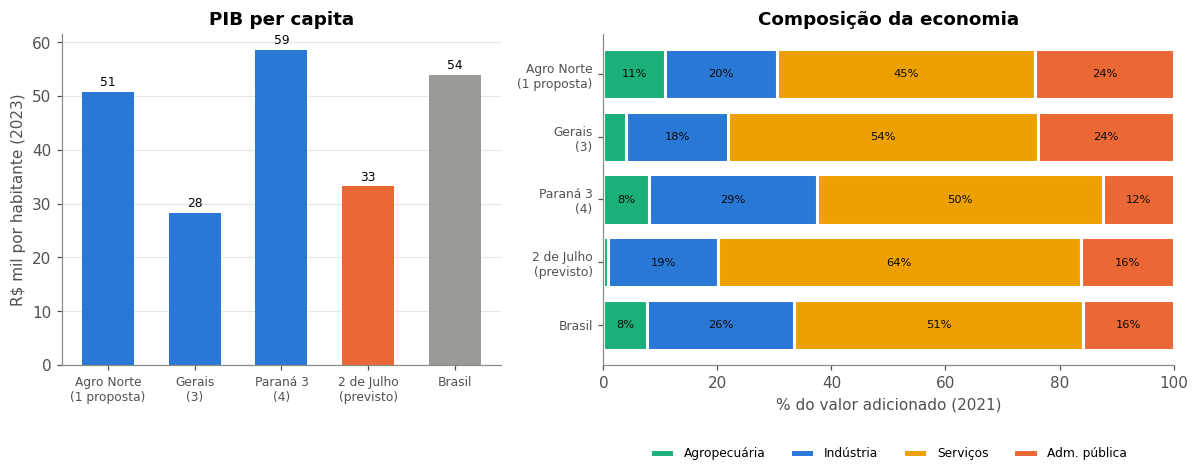

                       n_municipios  populacao_mil  pib_per_capita  pct_agro  \
leilao                                                                         
Rota Agro Norte (CN5)            11       1035.218       50818.441     0.108   
Rota das Gerais                  30       1152.606       28324.182     0.040   
Paraná Lote 3                    20       1554.678       58627.090     0.081   
Rota 2 de Julho                  17       4068.329       33224.199     0.008   
Brasil (referência)            5570     203080.757       53886.669     0.077   

                       pct_munic_adm_publica_principal  
leilao                                                  
Rota Agro Norte (CN5)                            0.273  
Rota das Gerais                                  0.667  
Paraná Lote 3                                    0.000  
Rota 2 de Julho                                  0.412  
Brasil (referência)                                NaN  


In [5]:
fin = ["Rota Agro Norte (CN5)", "Rota das Gerais", "Paraná Lote 3", "Rota 2 de Julho", "Brasil (referência)"]
reg = regiao.set_index("leilao").loc[fin]
nomes = ["Agro Norte\n(1 proposta)", "Gerais\n(3)", "Paraná 3\n(4)", "2 de Julho\n(previsto)", "Brasil"]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1, 1.3]})

# (a) renda
cores = [AZUL] * 3 + [LARANJA, CINZA]
barras = a1.bar(nomes, reg["pib_per_capita"] / 1000, color=cores, width=0.6)
a1.bar_label(barras, fmt="%.0f", fontsize=8, padding=2)
a1.set_ylabel("R$ mil por habitante (2023)")
a1.set_title("PIB per capita")
a1.tick_params(axis="x", labelsize=8)

# (b) composição setorial, barras empilhadas horizontais
setores = [("pct_agro", "Agropecuária", VERDE), ("pct_industria", "Indústria", AZUL),
           ("pct_servicos", "Serviços", AMARELO), ("pct_adm_publica", "Adm. pública", LARANJA)]
esq = np.zeros(len(reg))
for col, rot, cor in setores:
    v = reg[col].values * 100
    a2.barh(nomes, v, left=esq, color=cor, edgecolor="white", linewidth=2, label=rot)
    for y, (l, w) in enumerate(zip(esq, v)):
        if w >= 6: a2.text(l + w / 2, y, f"{w:.0f}%", ha="center", va="center", fontsize=7.5, color="#0b0b0b")
    esq += v
a2.invert_yaxis(); a2.set_xlim(0, 100); a2.grid(axis="y", visible=False)
a2.set_xlabel("% do valor adicionado (2021)")
a2.set_title("Composição da economia")
a2.legend(loc="lower center", bbox_to_anchor=(0.5, -0.32), ncol=4, frameon=False, fontsize=8)
a2.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

print(reg[["n_municipios", "populacao_mil", "pib_per_capita", "pct_agro", "pct_munic_adm_publica_principal"]].round(3))

**Leitura: a economia da região não segue a escada.**
- **Renda:** a Rota das Gerais tem a região mais pobre (R$ 28 mil por habitante, metade da média do Brasil) e mesmo assim atraiu três propostas. A Agro Norte é mais rica que a média brasileira e atraiu uma só.
- **Agro:** a Agro Norte é a mais dependente do agro (11%) e foi a que ninguém disputou; o Paraná 3, mais industrial, teve a maior briga. Pode haver alguma relação, mas três pontos não sustentam uma conclusão.
- **Dependência do governo:** em dois terços dos municípios da Rota das Gerais, a maior atividade é a administração pública, e isso não afastou ninguém.

**Por que a região importa menos do que eu esperava.** Quem paga o pedágio não é só a economia local, é o caminhão que atravessa o corredor. Na Rota das Gerais, 47% do tráfego é de caminhões, muitos de passagem entre o Nordeste e o Sudeste. Então a próxima hipótese é o tráfego.

## 5. E o tráfego?

**Escolhas e motivos**
- **Fonte:** os estudos de demanda que acompanham cada edital (contagens de veículos em pontos da rodovia).
- **Medida:** volume médio diário nos pontos de contagem, nos dois sentidos, e a parcela de caminhões. Caminhão importa porque paga por eixo: um caminhão de 6 eixos paga seis vezes a tarifa de um carro.
- **Cuidado com a comparação:** cada estudo usa um ano-base e uma definição própria (o da Agro Norte exclui motos e ônibus; o do Paraná 3 foi lido de gráficos, com margem de cerca de 10%). Comparo **ordem de grandeza**, não casas decimais.

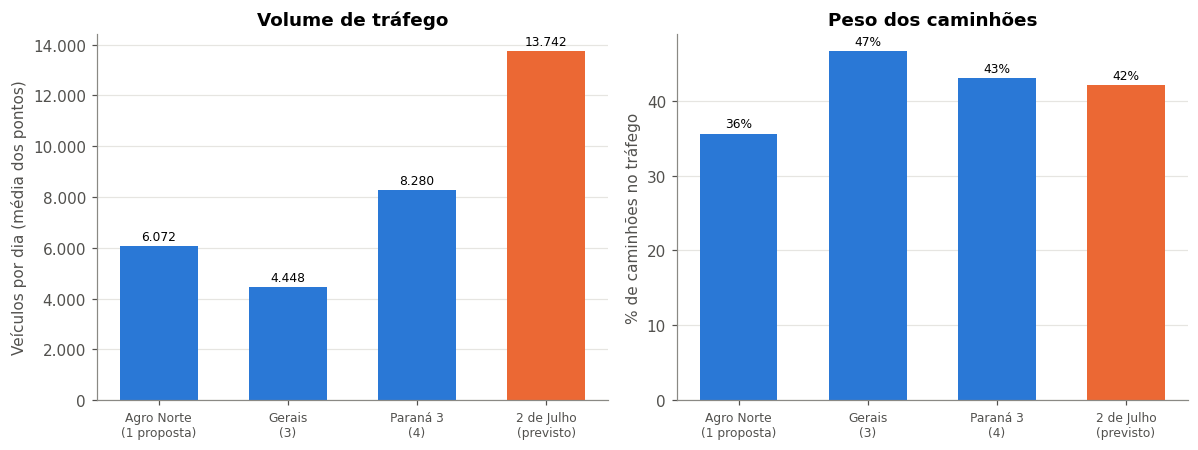

In [6]:
traf = df.set_index("leilao").loc[fin[:4], ["vdma_contagem", "pct_caminhoes"]]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
cores = [AZUL] * 3 + [LARANJA]
b = a1.bar(nomes[:4], traf["vdma_contagem"], color=cores, width=0.6)
a1.bar_label(b, labels=[f"{v:,.0f}".replace(",", ".") for v in traf["vdma_contagem"]], fontsize=8, padding=2)
a1.set_ylabel("Veículos por dia (média dos pontos)")
a1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
a1.set_title("Volume de tráfego")
a1.tick_params(axis="x", labelsize=8)

b = a2.bar(nomes[:4], traf["pct_caminhoes"] * 100, color=cores, width=0.6)
a2.bar_label(b, fmt="%.0f%%", fontsize=8, padding=2)
a2.set_ylabel("% de caminhões no tráfego")
a2.set_title("Peso dos caminhões")
a2.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

**Leitura: o tráfego também não segue a escada.** A Agro Norte tem *mais* tráfego que a Rota das Gerais (cerca de 6.100 contra 4.450 veículos por dia) e, mesmo assim, só um interessado. Excluindo o trecho urbano de Porto Velho, a média cai para cerca de 5.400, ainda acima da Gerais.

Dois detalhes da Agro Norte ajudam a entender o desinteresse, embora não provem nada:
- A **tarifa teto** final ficou em R$ 0,19 por km, contra R$ 0,13 na Rota das Gerais. Pedágio alto numa rodovia de pista simples aumenta o risco político.
- O estudo de demanda conclui que **quase não há rota de fuga**. É bom para a receita, mas também quer dizer que o usuário não tem alternativa ao pedágio, o que tende a gerar pressão contra a tarifa.

A Rota 2 de Julho tem o maior tráfego dos quatro (cerca de 13.700 veículos por dia, puxado pela BR-324 perto de Salvador).

## 6. Conclusão da triagem

**O que aprendi**
1. O desconto depende sobretudo de **quantos concorrentes aparecem**.
2. **Nenhum fundamento observável antes do leilão** (capex, duplicação, TIR de referência, economia regional, tráfego) previu essa concorrência nos lotes analisados. Ela parece depender de fatores que não estão nos dados: quem tinha caixa e apetite naquele momento, quem já opera trechos vizinhos, como o mercado enxerga o risco de cada estado.

**O que isso muda no modelo.** Se não dá para prever o desconto do leilão, não faz sentido usá-lo como premissa. O modelo de project finance vai fazer a pergunta ao contrário: **qual é o desconto máximo que o investidor pode oferecer e ainda atingir o retorno exigido?** Esse número será comparado com a faixa histórica:

| Cenário de disputa | Desconto típico |
|---|---|
| Sem concorrência | ~0% |
| Disputa moderada | ~15% |
| Disputa forte | ~25% |

Se o desconto máximo do investidor ficar acima de 25%, ele ganha em quase qualquer cenário. Se ficar abaixo de 15%, só vence se ninguém aparecer.

**Limitações**
- Poucos leilões por grupo; as conclusões são indícios, não testes estatísticos.
- Algumas listas de municípios são aproximadas, e os estudos de tráfego usam definições diferentes.
- Faltam desconto ou número de propostas em alguns leilões.

## 7. O ativo escolhido: Rota 2 de Julho

O modelo de project finance vai estudar a **Rota 2 de Julho** (BR-116 e BR-324, na Bahia), com leilão marcado para **18/12/2026**.

**Por que esse lote**
- **É uma previsão ao vivo.** Os outros finalistas já foram leiloados, então a resposta é conhecida. Na Rota 2 de Julho, dá para calcular o desconto máximo *antes* do leilão e, depois do dia 18, comparar com o lance vencedor.
- **É o maior e o mais movimentado dos finalistas:** R$ 14,3 bilhões de capex e cerca de 13.700 veículos por dia nos pontos de contagem.
- **Tem os riscos mais interessantes para modelar:** obra grande, trecho urbano perto de Salvador (BR-324), renda regional abaixo da média do país e TIR de referência de 12,5%, num ciclo de juros altos.

**O que a triagem deixa para o modelo**
- O desconto vencedor não é previsível a partir dos fundamentos; o modelo calcula o **desconto máximo** que um investidor pode oferecer.
- Faixas de comparação: ~0% (sem disputa), ~15% (disputa moderada), ~25% (disputa forte).
- Cenários a testar: tráfego abaixo do estudo (fuga e trecho urbano), estouro de capex e custo da dívida até a data do leilão.